# EDA 2

In [ ]:
!pip install biopython py3Dmol ipywidgets openpyxl rdkit

In [1]:
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw

from s3helper import simple_download_from_s3

In [2]:
# read dataframe
df = pd.read_excel("/home/ec2-user/SageMaker/data/raw/df_ICA_bionemo_eval_20250219.xlsx")
df.head()

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN
2,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN
3,BCS-CO63781,['BCS-CO63781'],CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1,120.0,92.0,NaN,NaN,NaN,NaN,1.11,2.72,1710.00,NaN
4,BCS-DC54916,['BCS-DC54916'],C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...,397.0,302.0,NaN,NaN,NaN,NaN,2.85,2.81,10.15,NaN


In [3]:
df.shape

(18806, 13)

In [4]:
# clean SMILES column 
def extract_smiles(text):
    if isinstance(text, str) and '|' in text:
        return text.split('|')[0]
    return text

# Create a new column with the cleaned SMILES
df['clean_smiles'] = df['std_smiles'].apply(extract_smiles)

In [5]:
df.head()

,SUBSTANCE,SUBSTANCE_KEYS,std_smiles,AI_H,HSEC,AVEFA_PO_PROF,Lolium_PO_PROF,TRZAX_PO_PROF,AMAPA_PO_SEC_PROF,LOGD_neutral,LOGD_acid,SOL_mgL,SIP,clean_smiles
0,BCS-DS23822,['BCS-DS23822'],C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...,318.0,317.0,NaN,NaN,NaN,NaN,0.89,1.93,3050.00,NaN,C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2c...
1,BCS-DH85862,['BCS-DH85862'],Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...,338.0,231.0,NaN,NaN,NaN,NaN,2.72,2.80,28.30,NaN,Cc1cc(F)cc(C2=NO[C@@](C)(C(=O)N[C@H]3C=C[C@@H]...
2,BCS-CS64954,['BCS-CS64954'],COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1,0.0,0.0,NaN,NaN,NaN,NaN,1.79,1.77,68.65,NaN,COc1ccc(C2=NOC(C)(C(=O)NC3CC3)C2)cc1
3,BCS-CO63781,['BCS-CO63781'],CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1,120.0,92.0,NaN,NaN,NaN,NaN,1.11,2.72,1710.00,NaN,CC1(C(=O)CCCC(=O)O)CC(c2cc(Cl)cc(Cl)c2)=NO1
4,BCS-DC54916,['BCS-DC54916'],C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...,397.0,302.0,NaN,NaN,NaN,NaN,2.85,2.81,10.15,NaN,C=C[C@]1(C(=O)NCc2ccnc(OC)c2)CC(c2cc(F)cc(F)c2...


In [6]:
duplicates = df['std_smiles'].value_counts()
no_duplicates = duplicates[duplicates > 1]
print(duplicates)
print("########")
print(f"Total duplicates: {no_duplicates.sum()}")

std_smiles
C=C[C@]1(C(=O)N[C@H]2CO[C@@H](C(=O)O)C2)CC(c2ccc(F)c(C)c2)=NO1 |a:2,&1:6,9| Product1    1
CCCc1ncc(CNC(=O)C2(CF)CC(c3cc(F)cc(F)c3)=NO2)o1                                         1
CN(C)C(=O)C1(C)CC(C2CC2)N(c2cc(Cl)cc(Cl)c2)O1                                           1
COc1ccc(C(C#N)NC(=O)C2(OC)CC(c3cc(F)cc(F)c3)=NO2)cn1                                    1
[O-][n+]1onc(-c2ccccc2)c1-c1ccccc1                                                      1
                                                                                       ..
CCOC(=O)CC[C@H](C)NC(=O)[C@]1(c2ccc(Cl)cc2)CC(C)=NO1 |a:7,&1:12| Product1               1
COc1ccc(COC(=O)C[C@H](C)NC(=O)[C@@]2(OC)CC(c3cc(C)cc(F)c3)=NO2)cc1                      1
CC1(C(=O)NCc2ccnc(S)n2)CC(c2cc(F)cc(F)c2)=NO1                                           1
CCOC(=O)C1(C)CC(C(C)(C)c2ccccc2)=NO1                                                    1
CSCCOC(=O)[C@@H]1C=C[C@H](NC(=O)[C@]2(C)CC(c3cc(F)cc(Cl)c3)=NO2)C1 |a:7,10,&1:14|       1

In [7]:
duplicates = df['clean_smiles'].value_counts()
no_duplicates = duplicates[duplicates > 1]
print("########")
print(f"Total duplicates based on clean smiles: {no_duplicates.sum()}")

########
Total duplicates based on clean smiles: 206


In [ ]:
# the smiles have douplicates if extension is excluded.
#df.drop_duplicates(subset="clean_smiles")

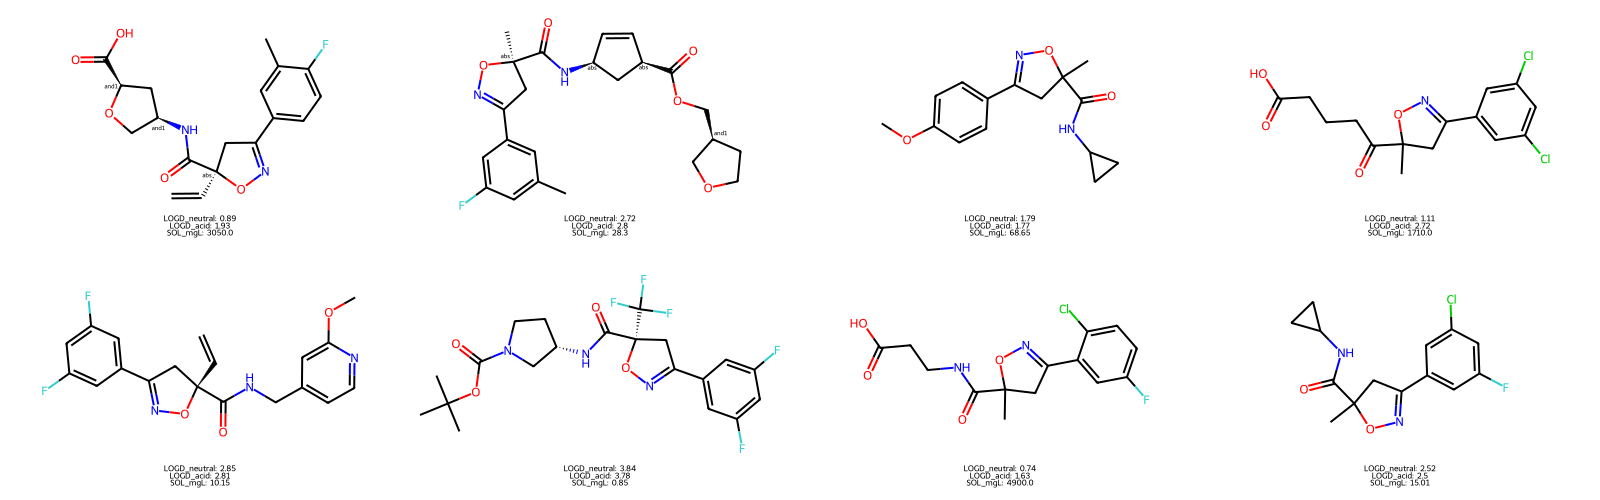

In [15]:

# Convert the first 5 SMILES strings to RDKit molecule objects
molecules = [Chem.MolFromSmiles(smiles) for smiles in df['std_smiles'].iloc[:8]]

# Create legends for the molecules
legends = [
    f"LOGD_neutral: {row['LOGD_neutral']}\nLOGD_acid: {row['LOGD_acid']}\nSOL_mgL: {row['SOL_mgL']}"
    for _, row in df.iloc[:8].iterrows()
]

# Draw the molecules in a grid
Draw.MolsToGridImage(molecules, molsPerRow=4, subImgSize=(400, 250), legends=legends)